## https://github.com/2026739-Jose/CA-1-Capstone-Project_Stats-for-Data-Analytics.git

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load the master dataset
df = pd.read_csv("irish_dairy_master_dataset.csv")

# Display basic descriptive statistics for numerical columns
summary_stats = df[
    [
        "Milk_Intake_Million_Litres",
        "CPM12_Diesel_Index",
        "Avg_Temperature_C",
    ]
].describe()
print(summary_stats)

       Milk_Intake_Million_Litres  CPM12_Diesel_Index  Avg_Temperature_C
count                  138.000000          138.000000         138.000000
mean                   714.728333          105.329203          10.508333
std                    329.793798           16.499028           3.997257
min                    160.500000           69.940000           4.130000
25%                    383.530000           95.412500           6.982500
50%                    782.260000           99.600000          10.185000
75%                   1022.847500          119.400000          14.415000
max                   1181.660000          156.770000          18.250000


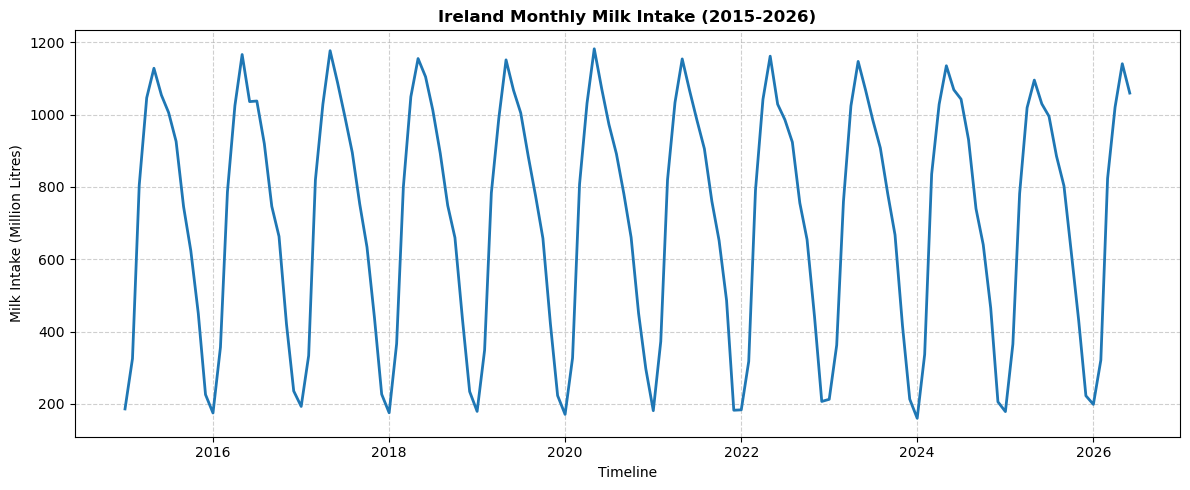

In [3]:

plt.figure(figsize=(12, 5))
plt.plot(
    pd.to_datetime(df["Date"]),
    df["Milk_Intake_Million_Litres"],
    color="tab:blue",
    linewidth=2,
)
plt.title(
    "Ireland Monthly Milk Intake (2015-2026)", fontsize=12, fontweight="bold"
)
plt.xlabel("Timeline", fontsize=10)
plt.ylabel("Milk Intake (Million Litres)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("milk_intake_trend.png")
plt.show()

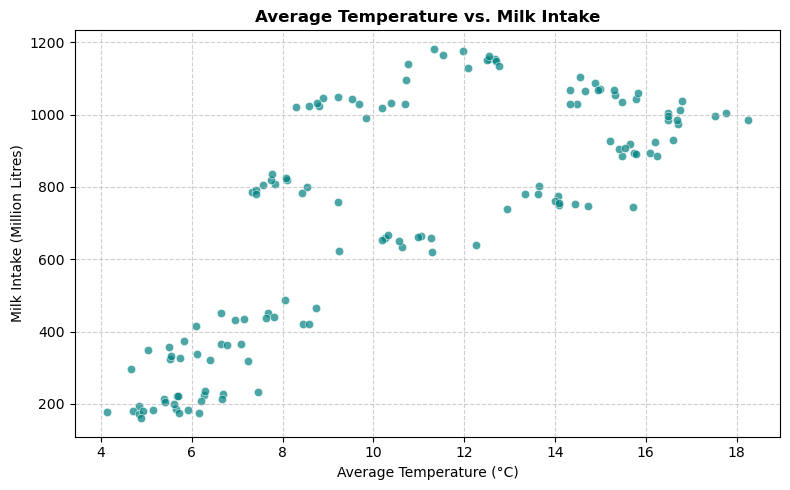

In [4]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Avg_Temperature_C",
    y="Milk_Intake_Million_Litres",
    color="teal",
    alpha=0.7,
)
plt.title(
    "Average Temperature vs. Milk Intake", fontsize=12, fontweight="bold"
)
plt.xlabel("Average Temperature (°C)", fontsize=10)
plt.ylabel("Milk Intake (Million Litres)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("temp_vs_milk_scatter.png")
plt.show()

C:\Users\Pepe\AppData\Local\Temp\ipykernel_15212\1566512213.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


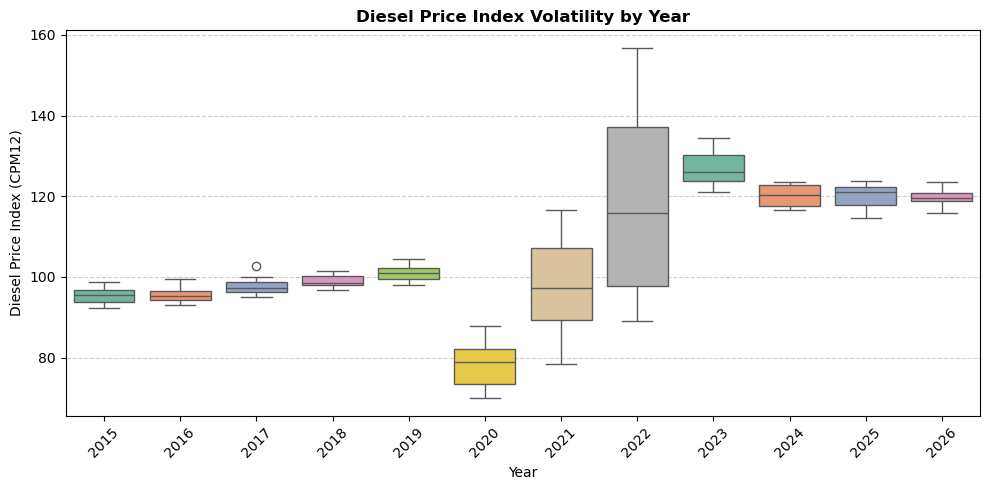

In [5]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df, x="Year", y="CPM12_Diesel_Index", palette="Set2"
)
plt.title(
    "Diesel Price Index Volatility by Year", fontsize=12, fontweight="bold"
)
plt.xlabel("Year", fontsize=10)
plt.ylabel("Diesel Price Index (CPM12)", fontsize=10)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("diesel_boxplot.png")
plt.show()

In [6]:
from scipy.stats import binom

# Parameters for the Binomial model
n_trials = 20  # Number of machines inspected in the plant
p_success = (
    0.05  # Estimated probability of failure under peak load conditions (5%)
)

# 1. PMF: Probability of EXACTLY 1 machine failing P(X = 1)
prob_exact_1 = binom.pmf(1, n_trials, p_success)

# 2. CDF: Probability of AT MOST 2 machines failing P(X <= 2)
prob_at_most_2 = binom.cdf(2, n_trials, p_success)

# 3. Complement: Probability of MORE THAN 2 machines failing P(X > 2) (Critical Risk)
prob_critical_risk = 1 - binom.cdf(2, n_trials, p_success)

print(f"Exact 1 failure P(X=1): {prob_exact_1:.4f}")
print(f"At most 2 failures P(X<=2): {prob_at_most_2:.4f}")
print(f"Critical risk P(X>2): {prob_critical_risk:.4f}")

Exact 1 failure P(X=1): 0.3774
At most 2 failures P(X<=2): 0.9245
Critical risk P(X>2): 0.0755


In [7]:
from scipy.stats import poisson

# Average rate of high-exposure operational events per year/month (lambda)
# Derived from our dataset observations
lambda_rate = 3.0

# Calculate probability of observing exactly k = 4 events in a period
prob_poisson_exact = poisson.pmf(4, mu=lambda_rate)

# Calculate cumulative probability of receiving up to 2 alerts P(X <= 2)
prob_poisson_cumulative = poisson.cdf(2, mu=lambda_rate)

print(f"Poisson Exact P(X=4): {prob_poisson_exact:.4f}")
print(f"Poisson Cumulative P(X<=2): {prob_poisson_cumulative:.4f}")

Poisson Exact P(X=4): 0.1680
Poisson Cumulative P(X<=2): 0.4232


In [8]:
from scipy.stats import norm
import matplotlib.pyplot as plt

mu = 714.73
sigma = 329.79

# Evaluate the probability of monthly milk intake exceeding 1,000 million litres P(X > 1000)
threshold_milk = 1000.0
prob_exceed_1000 = 1 - norm.cdf(threshold_milk, loc=mu, scale=sigma)

print(f"Probability of milk intake exceeding 1,000 million litres: {prob_exceed_1000:.4f} ({prob_exceed_1000 * 100:.2f}%)")

Probability of milk intake exceeding 1,000 million litres: 0.1935 (19.35%)
